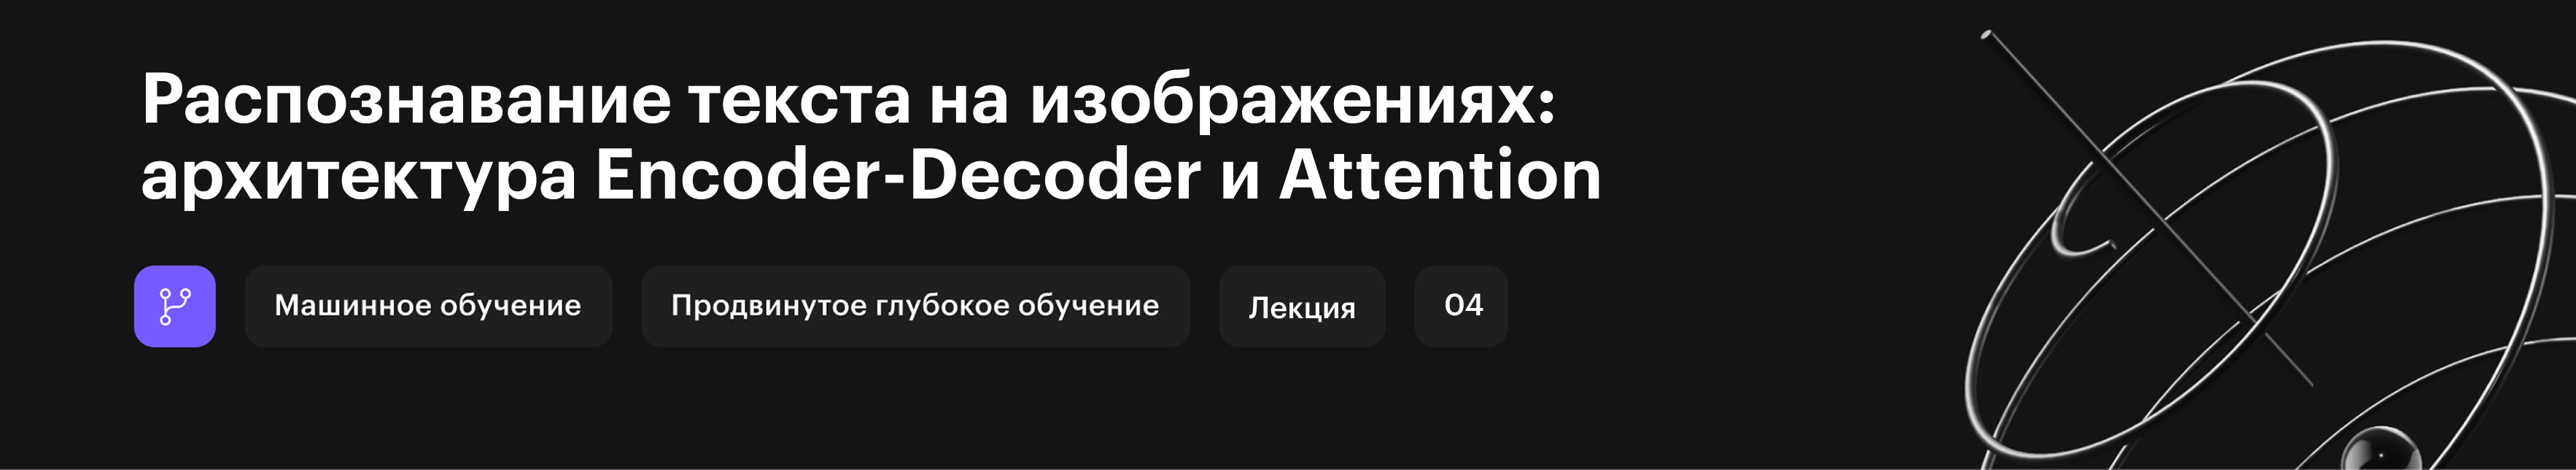

## 4. Генеративная модель `Encoder-Decoder` с механизмом внимания

### План

1. `Encoder–Decoder` — архитектура для задач `Seq2Seq`.
2. `Attention Mechanisms` — механизм внимания в моделях `Seq2Seq`.
3. `Teacher Forcing` — механизм обучения `Seq2Seq`-моделей.
4. `Greedy Search`, `Exhaustive Search` и `Beam Search` — cтратегии декодирования последовательностей.

In [ ]:
import torch.nn.functional as F
import plotly.graph_objs   as go
import torch.optim         as optim
import torch.nn            as nn
import numpy               as np

import torch
import json
import os

from plotly.subplots import make_subplots
from tqdm            import tqdm

### `Encoder–Decoder` — архитектура для задач `Seq2Seq`

---

Модель `Encoder–Decoder` предназначена для решения задач преобразования одной последовательности в другую (*sequence-to-sequence*, **Seq2Seq**). К таким задачам относятся машинный перевод, распознавание речи, генерация текста, а также задачи оптического распознавания символов. Основная идея архитектуры состоит в том, что входная последовательность сначала преобразуется в компактное внутреннее представление, после чего на его основе генерируется выходная последовательность.

---

Архитектура состоит из двух основных компонентов: `энкодера (Encoder)` и `декодера (Decoder)`.

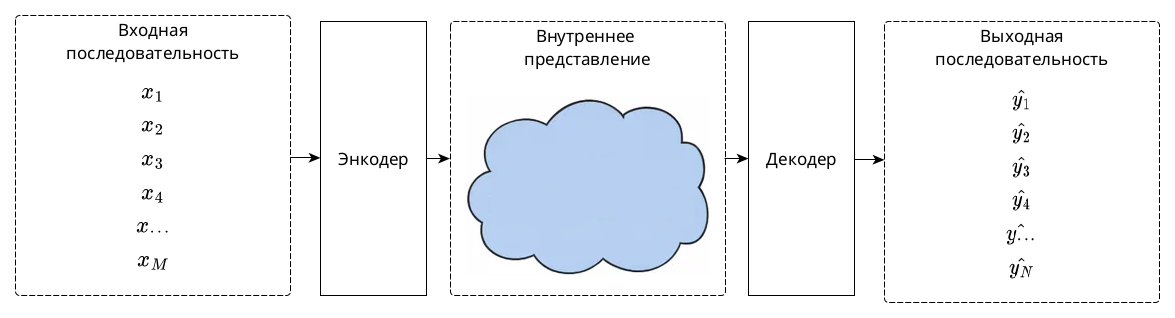

---

#### Encoder

Энкодер получает входную последовательность

$$
x = (x_1, x_2, \ldots, x_M)
$$

и последовательно обрабатывает её с помощью рекуррентной нейронной сети. На каждом шаге формируется скрытое состояние $h_m$, которое зависит от текущего входа и предыдущего состояния:

$$
h_m = f(x_m, h_{m-1}),
$$

где $f(\cdot)$ — рекуррентная функция, например **RNN**, **LSTM** или **GRU**.

После обработки всей последовательности формируется **контекстный вектор** $c$, который обычно соответствует последнему скрытому состоянию энкодера:

$$
c = h_M.
$$

Этот вектор содержит компактное представление всей входной последовательности.

---

#### Decoder

Декодер представляет собой другую рекуррентную сеть, которая генерирует выходную последовательность:

$$
\hat{y} = (\hat{y_1}, \hat{y_2}, \ldots, \hat{y_{N}}).
$$

На каждом шаге декодер вычисляет новое скрытое состояние на основе предыдущего состояния, ранее сгенерированного токена и контекстного вектора:

$$
s_n = f(\hat{y_{n-1}}, s_{n-1}, c).
$$

После этого вычисляется распределение вероятностей для следующего элемента последовательности:

$$
p(\hat{y_t} \mid \hat{y_{<t}}, c) = \text{softmax}(W s_n),
$$

где $W$ — матрица параметров выходного слоя.

---

### `Attention Mechanisms` — механизм внимания в моделях `Seq2Seq`

`Что такое механизм внимания и откуда он появился?`

Механизм внимания был впервые предложен в 2014 году в работе «Neural Machine Translation by Jointly Learning to Align and Translate» (Bahdanau et al., 2014). Он был разработан для улучшения нейронных машинных переводов — задачи, в которой одна последовательность (например, предложение на английском) должна быть переведена на другую (например, на французский).

До появления внимания архитектуры `Seq2Seq` работали так: энкодер преобразовывал входную последовательность в один фиксированный вектор, а затем декодер генерировал выходной текст, основываясь только на этом векторе. Это работало плохо для длинных предложений, потому что информация «сжималась» слишком сильно.

<img src="...
" alt="drawing" width="1200"/>

`Идея механизма внимания`

Механизм внимания позволяет декодеру «смотреть» на разные части входного предложения по мере генерации каждого слова, вместо того чтобы опираться только на один вектор. То есть он «взвешивает» выходы энкодера и решает, где сосредоточиться в данный момент.

Механизм внимания — это способ дать модели фокусироваться на самых релевантных участках входа при генерации каждого выхода.

<img src="...
SUVORK5CYII=
" alt="drawing" width="1200"/>

После успеха в машинном переводе внимание стали использовать во многих задачах.

#### Bahdanau Attention

**Bahdanau Attention** — это механизм внимания, предложенный в работе «Neural Machine Translation by Jointly Learning to Align and Translate» (Bahdanau et al., 2014). Основная идея метода состоит в том, что декодер на каждом шаге генерации выходной последовательности динамически вычисляет веса важности для всех скрытых состояний энкодера. Для этого используется небольшая нейронная сеть, которая оценивает «энергию» между текущим состоянием декодера $s_{t-1}$ и каждым состоянием энкодера $h_i$:

$$
e_{t,i} = v^T \tanh(W_s s_{t-1} + W_h h_i).
$$

Полученные значения нормализуются с помощью функции **softmax**, образуя веса внимания:

$$
\alpha_{t,i} = \text{softmax}(e_{t,i}).
$$

После этого формируется **контекстный вектор**, представляющий собой взвешенную сумму скрытых состояний энкодера:

$$
c_t = \sum_i \alpha_{t,i} h_i.
$$

Таким образом, модель получает возможность фокусироваться на различных частях входной последовательности при генерации каждого выходного элемента, что значительно улучшает качество моделей **Encoder–Decoder**, особенно для длинных последовательностей.

<div style="text-align:center;">
    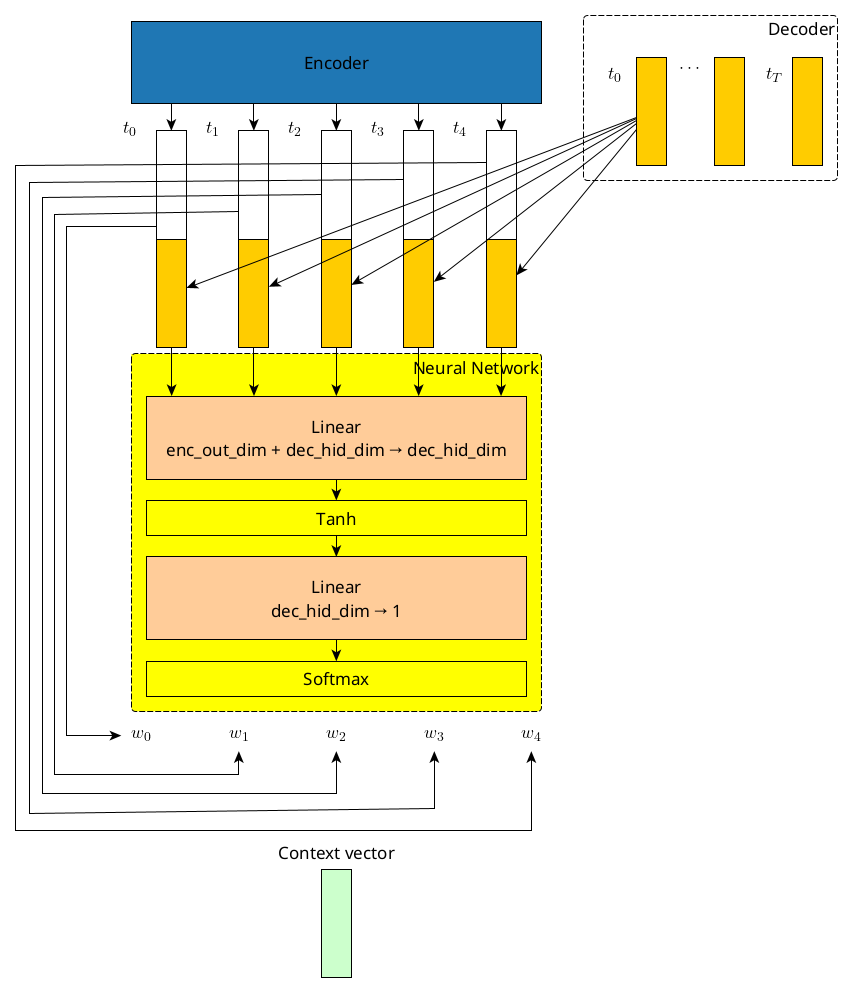
</div>

#### Luong Attention

**Luong Attention** — это механизм внимания, предложенный в работе «Effective Approaches to Attention-based Neural Machine Translation» (Luong et al., 2015). В отличие от механизма Bahdanau, где используется отдельная нейронная сеть для вычисления энергии, Luong Attention применяет более простые функции сходства между текущим скрытым состоянием декодера $s_t$ и скрытыми состояниями энкодера $h_i$. Наиболее распространённый вариант использует скалярное произведение:

$$
e_{t,i} = s_t^\top h_i.
$$

Также предложен более общий вариант, в котором используется линейное преобразование:

$$
e_{t,i} = s_t^\top W h_i.
$$

Полученные значения энергии нормализуются с помощью функции **softmax**, формируя веса внимания:

$$
\alpha_{t,i} = \text{softmax}(e_{t,i}).
$$

После этого вычисляется **контекстный вектор**, который представляет собой взвешенную сумму скрытых состояний энкодера:

$$
c_t = \sum_i \alpha_{t,i} h_i.
$$

Контекстный вектор затем объединяется с текущим состоянием декодера и используется для генерации следующего элемента выходной последовательности. Благодаря своей простоте и эффективности механизм **Luong Attention** широко применяется в моделях последовательного преобразования, особенно в задачах машинного перевода.

<div style="text-align:center;">
    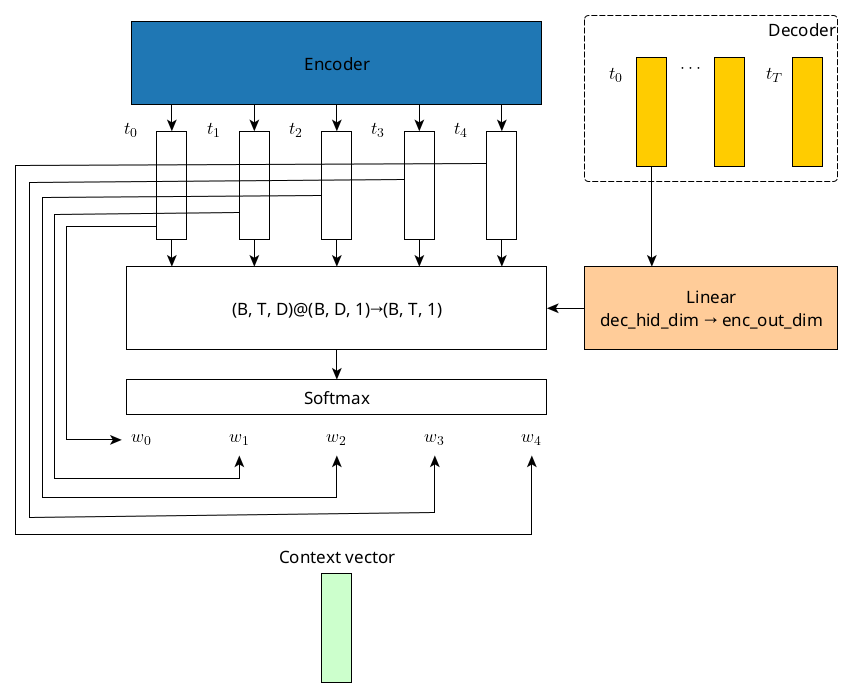
</div>

#### Scaled Dot-Product Attention

<div style="text-align:center;">
    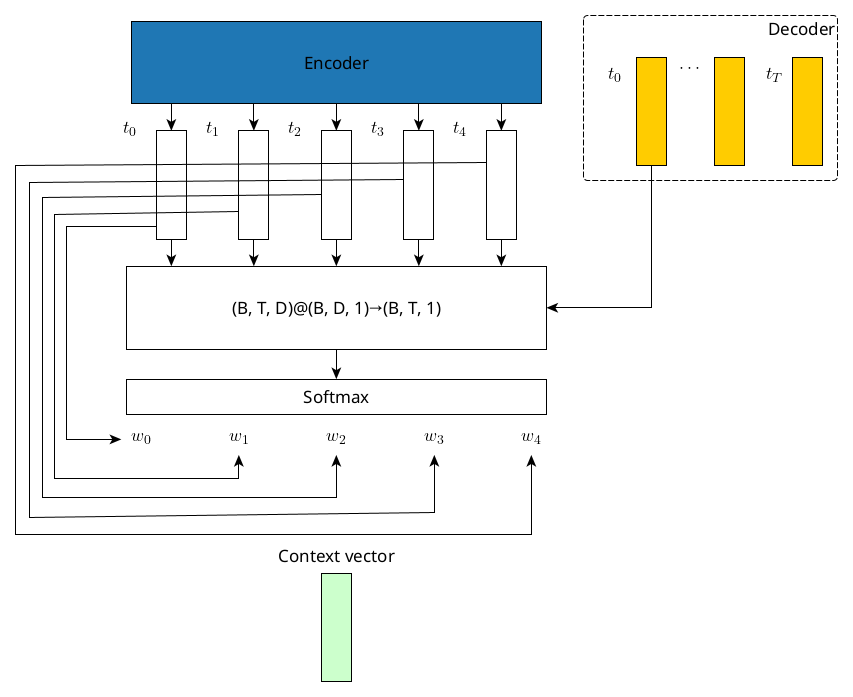
</div>

##### Нормировка в `ScaledDotProductAttention`
---

В классическом **dot-product attention** (Luong) оценка внимания вычисляется как скалярное произведение между векторами запроса (**query**) и ключа (**key**):

$$
e_{ij} = q_i^\top k_j.
$$

Однако, когда размерность векторов $d_k$ становится большой (например, 512 или 1024), значения $e_{ij}$ могут иметь **большую дисперсию**.  
После этого на них применяется `softmax`:

$$
\alpha_{ij} = \frac{\exp(e_{ij})}{\sum_{t} \exp(e_{it})}.
$$

Проблема в том, что при больших $e_{ij}$ экспонента становится **очень крутой** и `softmax` превращается почти в **«жёсткий максимум»**. Внимание концентрируется на одном элементе, а градиенты для остальных становятся почти нулевыми. Это **затрудняет обучение** и делает модель нестабильной.

---

Авторы трансформера предложили **нормировать** скалярное произведение, разделив его на корень из размерности ключей:

$$
e_{ij} = \frac{q_i^\top k_j}{\sqrt{d_k}}.
$$

Таким образом, если $q_i$ и $k_j$ — случайные векторы с нулевым средним и дисперсией 1, то дисперсия скалярного произведения $ q_i^\top k_j $ пропорциональна $ d_k $.  
Деление на $\sqrt{d_k}$ **стабилизирует распределение значений** $e_{ij}$, удерживая их в умеренных пределах.

---

- Уменьшает разброс значений $ e_{ij} $.
- Делает `softmax` более **равномерным** (не «выстреливает» в один элемент).
- Улучшает **градиентный поток** при обучении.
- Повышает **стабильность** и **скорость сходимости**.

#### Сравнение механизмов внимания

| Характеристика                        | **Bahdanau Attention (Additive)**                                                                 | **Luong Attention (Multiplicative)**                                                        | **Scaled Dot-Product Attention (Transformer)**                  |
| :------------------------------------ | :------------------------------------------------------------------------------------------------ | :------------------------------------------------------------------------------------------ | :-------------------------------------------------------------- |
| **Авторы и год**                      | Bahdanau et al., 2014 — *«Neural Machine Translation by Jointly Learning to Align and Translate»* | Luong et al., 2015 — *«Effective Approaches to Attention-based Neural Machine Translation»* | Vaswani et al., 2017 — *«Attention is All You Need»*            |
| **Тип внимания**                      | Аддитивное (additive)                                                                             | Мультипликативное (dot/general)                                                             | Масштабированное скалярное произведение (scaled dot-product)    |
| **Формула оценки (score)**            | $ e_{t,s} = v_a^T \tanh(W_h h_s + W_s s_{t-1}) $                                                  | $ e_{t,s} = s_t^T W_a h_s $ или $ s_t^T h_s $                                               | $ e_{t,s} = \frac{s_t^T h_s}{\sqrt{d_k}} $                      |
| **Тип операции**                      | Сложение (additive combination)                                                                   | Умножение (dot product)                                                                     | Умножение с масштабированием                                    |
| **Нелинейность**                      | Есть (`tanh`)                                                                                     | Нет                                                                                         | Нет                                                             |
| **Параметры**                         | Больше (доп. линейные слои + вектор v)                                                            | Меньше                                                                                      | Минимум (только размерность d)                                  |
| **Скорость вычислений**               | Медленнее                                                                                         | Быстрее                                                                                     | Самая быстрая (параллелизуется на GPU)                          |
| **Гибкость выравнивания (alignment)** | Высокая — может сравнивать вектора из разных пространств                                          | Требует схожести пространств энкодера и декодера                                            | Работает в любом пространстве (через линейные проекции Q, K, V) |
| **Стабильность обучения**             | Высокая, но медленная сходимость                                                                  | Быстрая, но чувствительна к масштабу скрытых состояний                                      | Очень стабильная благодаря делению на $\sqrt{d_k}$              |
| **Интерпретация**                     | «Нейросетевое» вычисление совместимости                                                           | Геометрическое сходство (угол между векторами)                                              | Нормализованная мера сходства (контрастная оценка)              |
| **Использование в моделях**           | Классические `seq2seq RNN`, ранние `NMT`                                                              | Поздние `seq2seq`, гибриды `CNN+RNN`                                                             | `Transformer`, `BERT`, `GPT`, `ViT` и почти все современные архитектуры |
| **Типичная область**                  | Машинный перевод, распознавание речи                                                              | Машинный перевод, OCR, Captioning                                                           | Любая область: NLP, CV, Audio                                   |
| **Сложность реализации**              | Средняя (нужно больше слоёв)                                                                      | Простая                                                                                     | Простая, но требует Q/K/V-проекций                              |
| **Интуитивная идея**                  | «Узнать, насколько хорошо состояния подходят друг другу»                                          | «Измерить похожесть состояний»                                                              | «Взвесить зависимости на основе нормализованной похожести»      |


#### Multilayer Perceptron Attention

В предыдущих механизмах внимания функция сходства между состоянием декодера и состояниями энкодера задавалась с помощью простых аналитических формул, например скалярного произведения или билинейного преобразования. Однако более гибкий подход заключается в том, чтобы **обучать функцию сходства с помощью небольшой нейронной сети**. В этом случае вместо фиксированной формулы используется параметризованный *scorer*, который принимает текущее скрытое состояние декодера \(s_t\) и скрытое состояние энкодера $h_i$, после чего вычисляет значение энергии:

$$
e_{t,i} = f_{\theta}(s_t, h_i),
$$

где $f_{\theta}$ — небольшая нейронная сеть с параметрами $\theta$. На практике входные представления часто объединяются (например, конкатенацией), после чего пропускаются через несколько линейных слоёв с нелинейностями:

$$
e_{t,i} = \text{Linear}\left([s_t ; h_i]\right).
$$

Полученные значения энергии нормализуются функцией **softmax**, формируя веса внимания:

$$
\alpha_{t,i} = \text{softmax}(e_{t,i}).
$$

Далее вычисляется **контекстный вектор** как взвешенная сумма скрытых состояний энкодера:

$$
c_t = \sum_i \alpha_{t,i} h_i.
$$

Использование нейронной сети в роли *scorer* позволяет модели **обучать более сложную функцию соответствия** между состояниями энкодера и декодера. Благодаря этому механизм внимания становится более гибким и способен лучше адаптироваться к структуре данных и конкретной задаче.

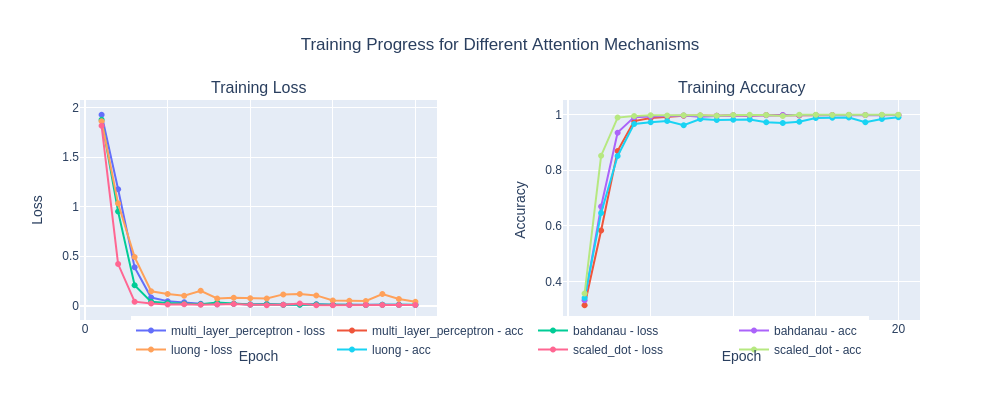

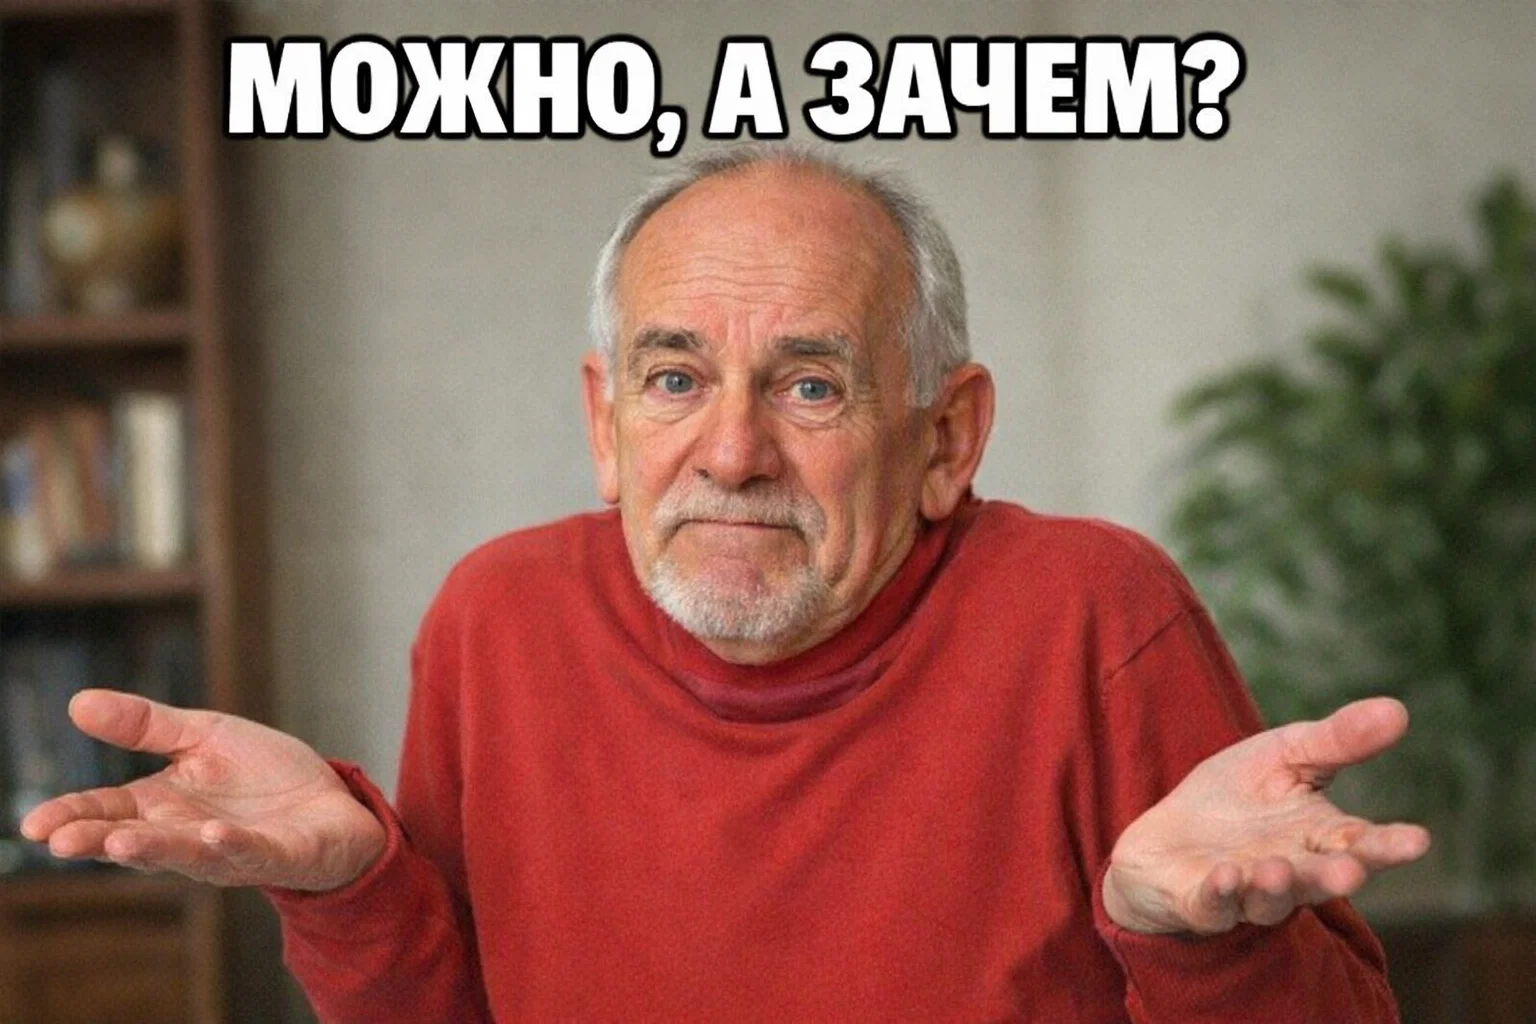

### `Teacher Forcing` — механизм обучения `Seq2Seq`-моделей

**Teacher Forcing** — это метод обучения рекуррентных моделей и архитектур **Encoder–Decoder**, при котором на каждом шаге декодера в качестве входа используется **истинный предыдущий элемент последовательности**, а не значение, сгенерированное самой моделью. Если выходная последовательность обозначается как $y = (y_1, y_2, \ldots, y_T)$, то на шаге $t$ декодер получает на вход корректное значение $y_{t-1}$, а не предсказание модели $\hat{y}_{t-1}$:

$$
p(y_t \mid y_{t-1}, s_t, c),
$$

где $s_t$ — скрытое состояние декодера, а $c$ — контекстный вектор. Такой подход существенно ускоряет обучение и делает процесс оптимизации более стабильным, поскольку ошибка модели не накапливается по мере генерации последовательности.

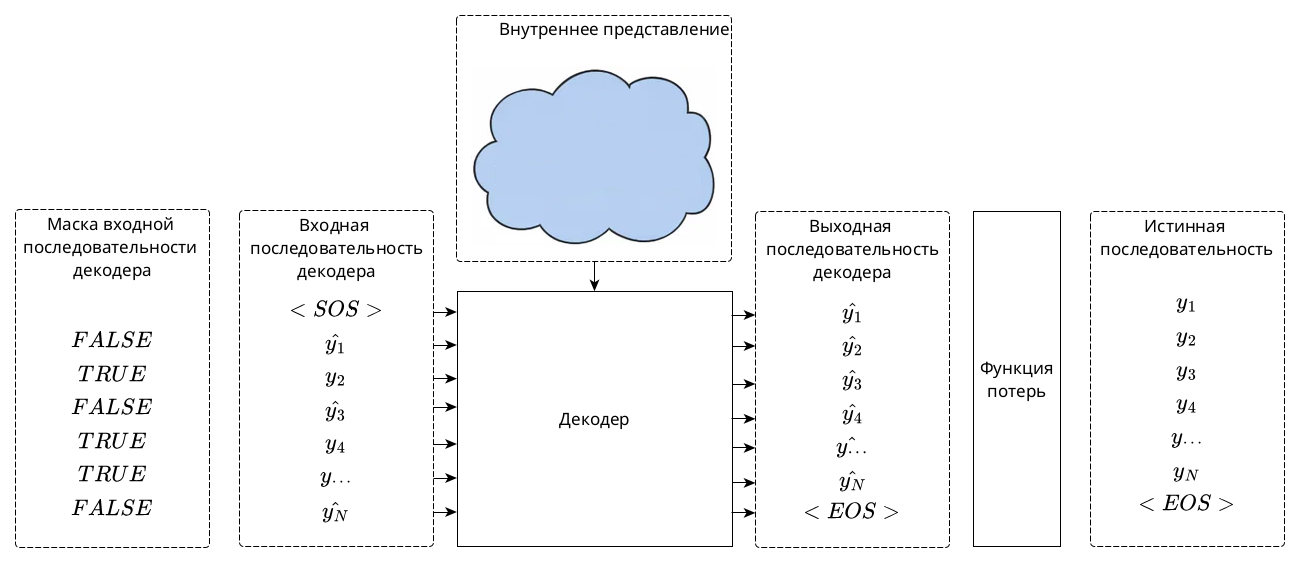

Однако при использовании **Teacher Forcing** возникает проблема **несоответствия между обучением и инференсом (exposure bias)**: во время генерации модель вынуждена использовать собственные предсказания в качестве входа. Для уменьшения этого эффекта часто применяют техники, такие как **Scheduled Sampling**, при которых модель постепенно переходит от использования истинных значений к использованию собственных предсказаний.

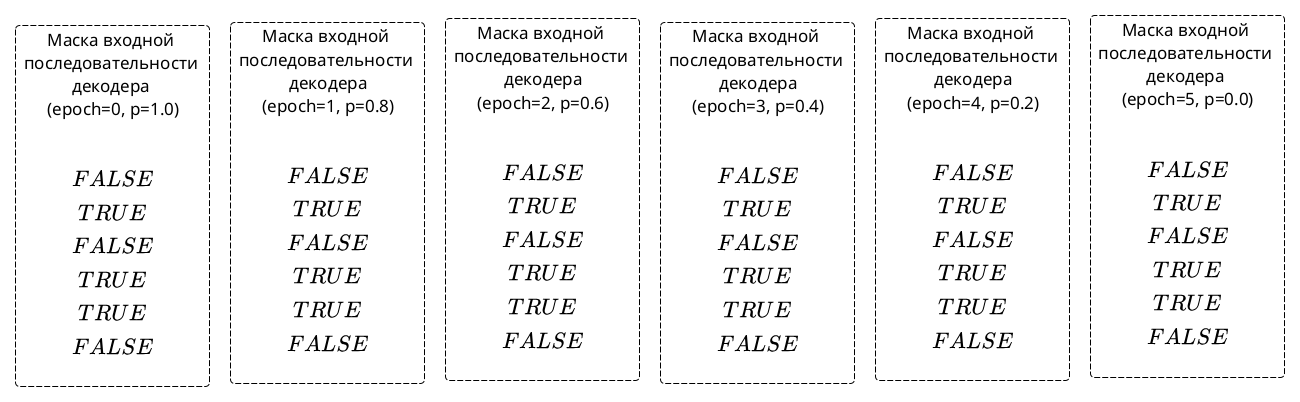

### `Greedy Search`, `Exhaustive Search` и `Beam Search` — cтратегии декодирования последовательностей.

`Общая постановка задачи`

Представим, что у нас есть задача генерации последовательности $Y = (y_1, y_2, \cdots, y_T)$, где каждое $y_i$ — это элемент последовательности (например, слово). Наша модель выдаёт вероятность всей последовательности $P(Y|X)$, где X — это входные данные (например, исходное предложение). Наша цель — найти наиболее вероятную выходную последовательность:

$$Y* = \arg\max_Y P(Y|X).$$

`Исчерпывающий поиск (Exhaustive Search)`

Алгоритм исследует все возможные последовательности и возвращает последовательность, которая имеет максимальную общую вероятность $P(Y|X)$. Это точное решение задачи $\arg\max_Y P(Y|X)$. Он гарантированно находит глобальный максимум, однако вычислительно неосуществим для сколь-либо длинных последовательностей. Если размер словаря $V=1000$, а длина последовательности $T=10$, число вариантов равно $1000^10$.

`Жадный поиск (Greedy Search)`

Алгоритм на каждом шаге выбирает слово с наивысшей вероятностью на текущем шаге, не задумываясь о будущих последствиях.

- $t_1$ : $y_1^{*} = \arg\max_{y_1} P(y_1 | X)$.
    
- $t_2$ : $y_2^{*} = \arg\max_{y_2} P(y_2 | X, y_1^{*})$.

- $t_3$ : $y_2^{*} = \arg\max_{y_3} P(y_3 | X, y_1^{*}, y_2^{*})$ и т. д.


Жадный поиск аппроксимирует полную вероятность последовательности $P(Y|X)$ как произведение максимумов условных вероятностей на каждом шаге:

$$P(Y|X) ≈ max_{y_1} P(y_1|X) \cdot max_{y_2} P(y_2|X, y_1^{*}) \cdot max_{y_3} P(y_3|X, y_1^{*}, y_2^{*}) \cdot ....$$

Он не ищет последовательность, максимизирующую общее произведение. Вместо этого он на каждом шаге максимизирует только один множитель этого произведения.

`Лучевой поиск (Beam Search)`

Это компромисс между двумя предыдущими методами. Лучевой поиск поддерживает k (ширина луча, beam width) наиболее перспективных гипотез на каждом шаге.

- Инициализация. Начинаем с $k$ самых вероятных первых слов ($y_1$).
- Расширение. Для каждой из $k$ гипотез рассматриваем все возможные следующие слова. Общее число гипотез становится $k × V$.
- Отбор. Из всех этих $k × V$ гипотез мы выбираем $top-k$ с наибольшей суммарной вероятностью на данный момент.
- Повтор. Шаги 2 и 3 повторяются до тех пор, пока все гипотезы не завершатся (например, специальным токеном $<EOS>$).

Лучевой поиск аппроксимирует поиск глобального максимума, но работает не со всем пространством, а с подмножеством из k наиболее вероятных кандидатов.

Он ищет последовательность, которая максимизирует не каждый шаг по отдельности, а совместную вероятность накопленного пути для $k$ кандидатов:

$$score(Y_{1:t}) = P(y₁, y₂, ..., y_t | X) = P(y_1|X) \cdot P(y_2|X, y_1) \cdot ... \cdot P(y_t|X, y_1, ..., y_{t-1}).$$

На каждом шаге он отбирает $k$ путей с наибольшим $score$.

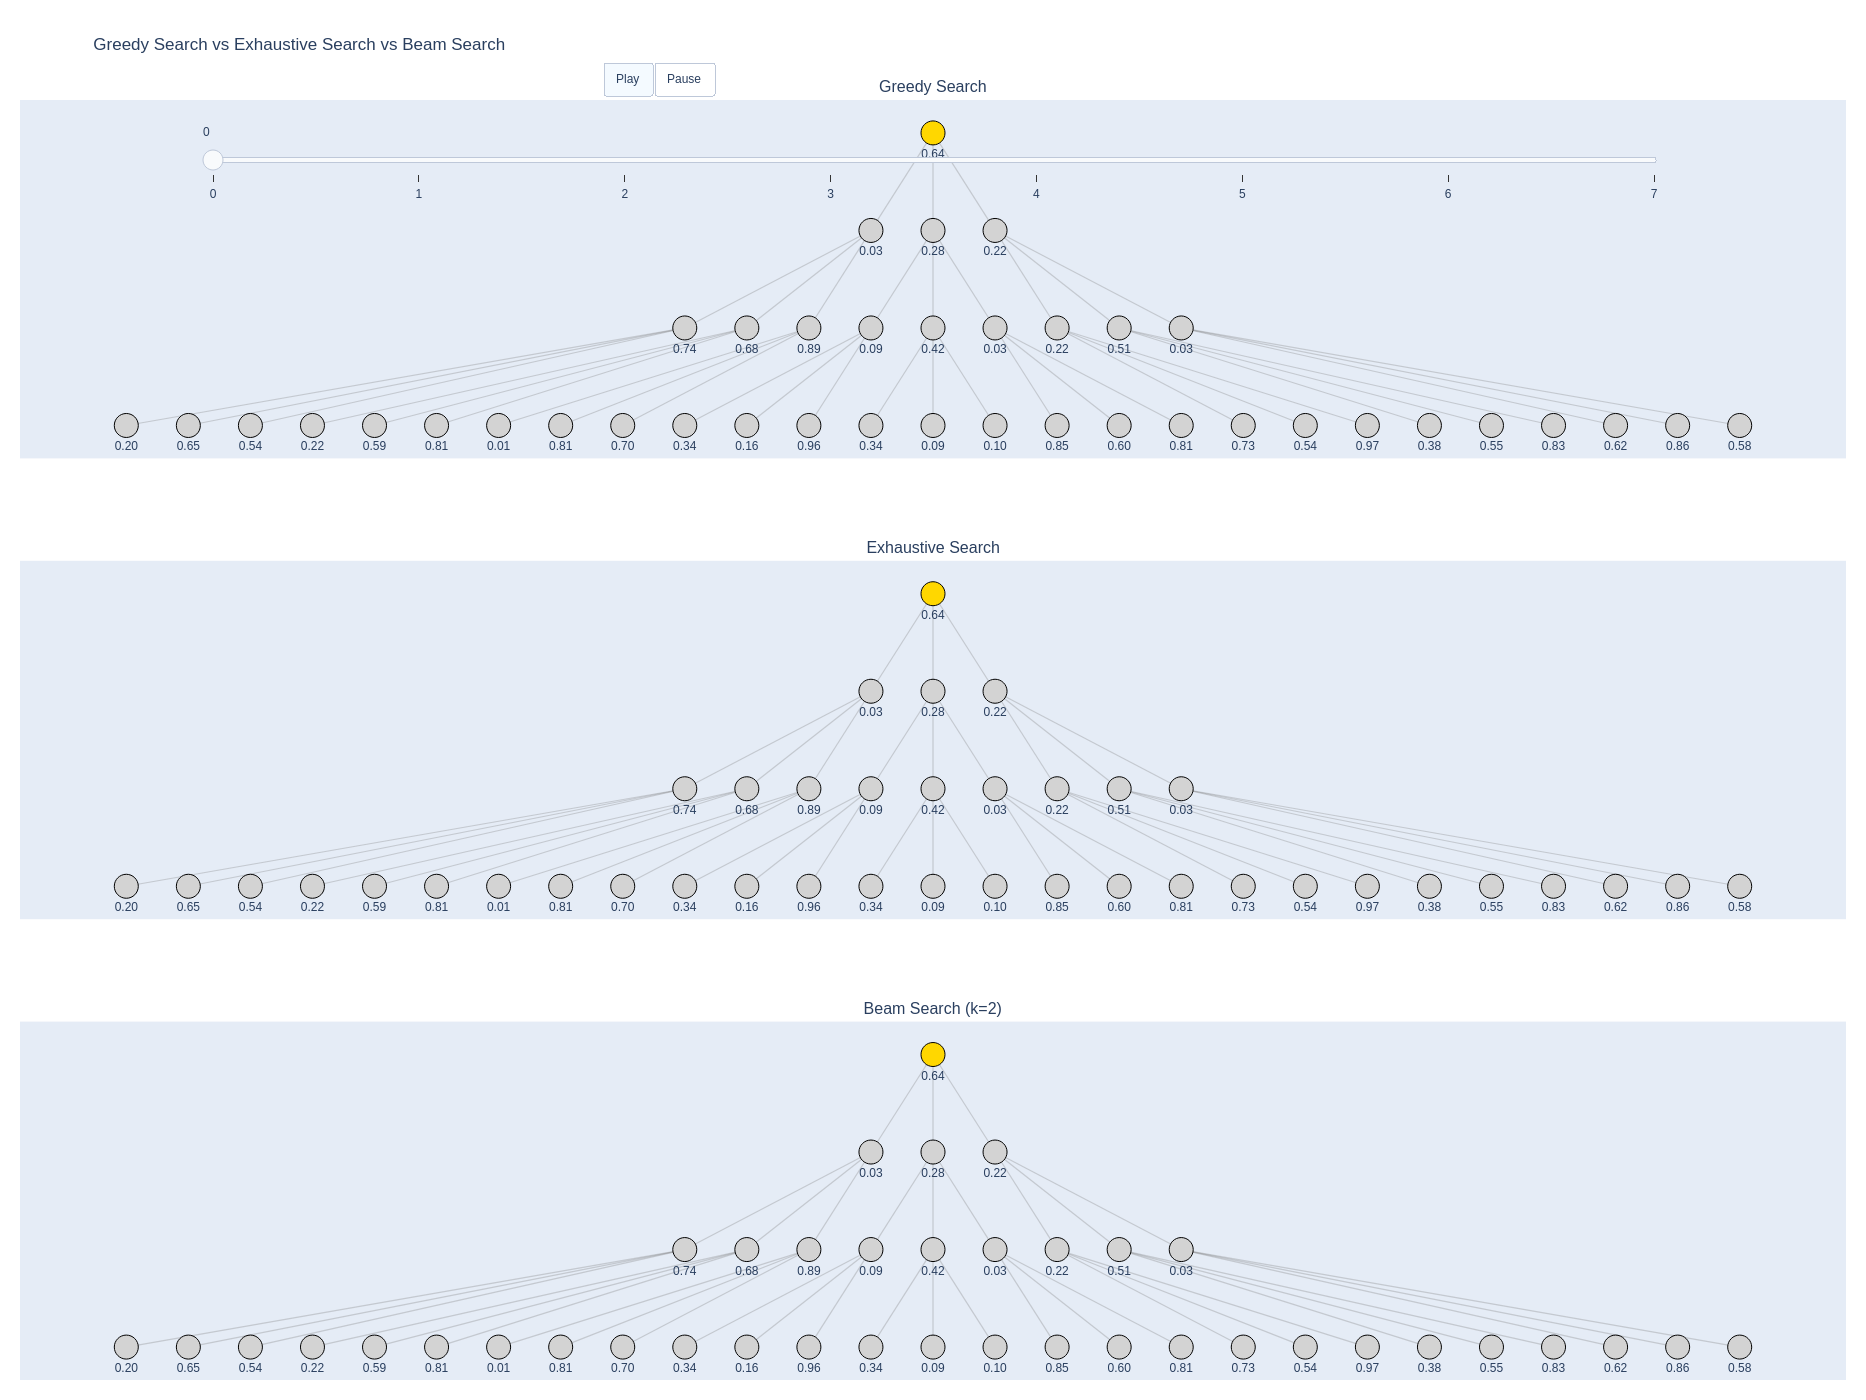

Saved HTML: search_algorithms_vertical.html
Saved PNG: search_algorithms_vertical.png
Saved GIF: search_algorithms_vertical.gif


In [ ]:
import math
import random
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import networkx as nx
import plotly.graph_objects as go
from plotly.subplots import make_subplots


SEED = 42
BRANCHING = 3
DEPTH = 3
BEAM_WIDTH = 2

FIG_WIDTH = 1200
FIG_HEIGHT = 1400

NODE_SIZE = 24

SAVE_HTML = True
SAVE_PNG = True
SAVE_GIF = True

HTML_NAME = "search_algorithms_vertical.html"
PNG_NAME = "search_algorithms_vertical.png"
GIF_NAME = "search_algorithms_vertical.gif"


@dataclass
class NodeInfo:
    node_id: str
    level: int
    value: float
    parent: Optional[str]


def build_layered_graph(branching: int = 3, depth: int = 3, seed: int = 42):
    random.seed(seed)

    G = nx.DiGraph()
    node_info: Dict[str, NodeInfo] = {}
    levels: List[List[str]] = []

    root = "L0_0"
    G.add_node(root)
    node_info[root] = NodeInfo(root, 0, random.random(), None)
    levels.append([root])

    for level in range(1, depth + 1):
        prev_nodes = levels[level - 1]
        current_nodes = []
        counter = 0

        for parent in prev_nodes:
            for _ in range(branching):
                nid = f"L{level}_{counter}"
                counter += 1
                G.add_node(nid)
                G.add_edge(parent, nid)
                node_info[nid] = NodeInfo(nid, level, random.random(), parent)
                current_nodes.append(nid)

        levels.append(current_nodes)

    return G, node_info, levels


def compute_positions(levels: List[List[str]]) -> Dict[str, Tuple[float, float]]:
    pos = {}
    for level, nodes in enumerate(levels):
        n = len(nodes)
        xs = [i - (n - 1) / 2 for i in range(n)]
        y = -level
        for i, node in enumerate(nodes):
            pos[node] = (xs[i], y)
    return pos


def softmax(xs: List[float]) -> List[float]:
    m = max(xs)
    exps = [math.exp(x - m) for x in xs]
    s = sum(exps)
    return [e / s for e in exps]


def assign_edge_probabilities(G: nx.DiGraph, node_info: Dict[str, NodeInfo]):
    edge_probs = {}
    for parent in G.nodes():
        children = list(G.successors(parent))
        if not children:
            continue
        vals = [node_info[c].value for c in children]
        probs = softmax(vals)
        for c, p in zip(children, probs):
            edge_probs[(parent, c)] = p
    return edge_probs


def path_edges(path: List[str]) -> List[Tuple[str, str]]:
    return [(path[i], path[i + 1]) for i in range(len(path) - 1)]


def path_log_score(path: List[str], edge_probs: Dict[Tuple[str, str], float]) -> float:
    if len(path) <= 1:
        return 0.0
    return sum(math.log(edge_probs[(path[i], path[i + 1])] + 1e-12) for i in range(len(path) - 1))


def build_greedy_trace(G: nx.DiGraph, edge_probs, levels):
    root = levels[0][0]
    current = root
    path = [root]
    frames = []

    frames.append({
        "selected_paths": [path.copy()],
        "candidate_paths": [],
        "frontier_nodes": [root],
    })

    for _level in range(1, len(levels)):
        children = list(G.successors(current))
        candidates = [path + [c] for c in children]
        best_child = max(children, key=lambda c: edge_probs[(current, c)])

        frames.append({
            "selected_paths": [path.copy()],
            "candidate_paths": candidates,
            "frontier_nodes": children,
        })

        path = path + [best_child]
        current = best_child

        frames.append({
            "selected_paths": [path.copy()],
            "candidate_paths": [],
            "frontier_nodes": [current],
        })

    frames.append({
        "selected_paths": [path.copy()],
        "candidate_paths": [],
        "frontier_nodes": [path[-1]],
    })
    return frames


def build_exhaustive_trace(G: nx.DiGraph, edge_probs, levels):
    root = levels[0][0]
    partial_paths = [[root]]
    frames = []

    frames.append({
        "selected_paths": [[root]],
        "candidate_paths": [],
        "frontier_nodes": [root],
    })

    for _level in range(1, len(levels)):
        candidates = []
        for p in partial_paths:
            for c in G.successors(p[-1]):
                candidates.append(p + [c])

        best_partial = max(candidates, key=lambda p: path_log_score(p, edge_probs))

        frames.append({
            "selected_paths": [best_partial],
            "candidate_paths": candidates,
            "frontier_nodes": [p[-1] for p in candidates],
        })

        partial_paths = candidates

        frames.append({
            "selected_paths": [best_partial],
            "candidate_paths": [],
            "frontier_nodes": [best_partial[-1]],
        })

    best_final = max(partial_paths, key=lambda p: path_log_score(p, edge_probs))
    frames.append({
        "selected_paths": [best_final],
        "candidate_paths": [],
        "frontier_nodes": [best_final[-1]],
    })
    return frames


def build_beam_trace(G: nx.DiGraph, edge_probs, levels, beam_width=2):
    root = levels[0][0]
    beam = [[root]]
    frames = []

    frames.append({
        "selected_paths": beam.copy(),
        "candidate_paths": [],
        "frontier_nodes": [root],
    })

    for _level in range(1, len(levels)):
        candidates = []
        for p in beam:
            for c in G.successors(p[-1]):
                candidates.append(p + [c])

        frames.append({
            "selected_paths": beam.copy(),
            "candidate_paths": candidates,
            "frontier_nodes": [p[-1] for p in candidates],
        })

        beam = sorted(
            candidates,
            key=lambda p: path_log_score(p, edge_probs),
            reverse=True,
        )[:beam_width]

        frames.append({
            "selected_paths": beam.copy(),
            "candidate_paths": [],
            "frontier_nodes": [p[-1] for p in beam],
        })

    frames.append({
        "selected_paths": [beam[0]],
        "candidate_paths": [],
        "frontier_nodes": [beam[0][-1]],
    })
    return frames


def make_edge_base_trace(G, pos):
    xs, ys = [], []
    for u, v in G.edges():
        x0, y0 = pos[u]
        x1, y1 = pos[v]
        xs += [x0, x1, None]
        ys += [y0, y1, None]

    return go.Scatter(
        x=xs,
        y=ys,
        mode="lines",
        line=dict(color="rgba(120,120,120,0.30)", width=1.2),
        hoverinfo="none",
        showlegend=False,
    )


def make_edge_probability_trace(G, pos, edge_probs):
    xs, ys, texts = [], [], []
    for u, v in G.edges():
        x0, y0 = pos[u]
        x1, y1 = pos[v]
        xs.append((x0 + x1) / 2)
        ys.append((y0 + y1) / 2)
        texts.append(f"{edge_probs[(u, v)]:.2f}")

    return go.Scatter(
        x=xs,
        y=ys,
        mode="text",
        text=texts,
        textfont=dict(size=10, color="black"),
        hoverinfo="none",
        showlegend=False,
    )


def make_path_trace(paths, pos, color="orange", width=4):
    xs, ys = [], []
    for p in paths:
        for u, v in path_edges(p):
            x0, y0 = pos[u]
            x1, y1 = pos[v]
            xs += [x0, x1, None]
            ys += [y0, y1, None]

    return go.Scatter(
        x=xs,
        y=ys,
        mode="lines",
        line=dict(color=color, width=width),
        hoverinfo="none",
        showlegend=False,
    )


def make_beam_path_traces(paths, pos):
    colors = ["orange", "crimson", "mediumseagreen", "mediumpurple", "deepskyblue"]
    traces = []
    for i, p in enumerate(paths):
        traces.append(make_path_trace([p], pos, color=colors[i % len(colors)], width=4))
    return traces


def make_node_trace(G, pos, node_info, selected_paths, frontier_nodes):
    selected_nodes = set()
    for p in selected_paths:
        selected_nodes.update(p)

    frontier_nodes = set(frontier_nodes)

    xs, ys, colors, texts, labels = [], [], [], [], []
    for n in G.nodes():
        x, y = pos[n]
        xs.append(x)
        ys.append(y)
        texts.append(f"{n}<br>value={node_info[n].value:.2f}")
        labels.append(f"{node_info[n].value:.2f}")

        if n in selected_nodes:
            colors.append("gold")
        elif n in frontier_nodes:
            colors.append("lightskyblue")
        else:
            colors.append("lightgray")

    return go.Scatter(
        x=xs,
        y=ys,
        mode="markers+text",
        text=labels,
        textposition="bottom center",
        hovertext=texts,
        hoverinfo="text",
        marker=dict(
            size=NODE_SIZE,
            color=colors,
            line=dict(color="black", width=1),
        ),
        showlegend=False,
    )


def algorithm_panel_traces(G, pos, node_info, edge_probs, state, mode="default", beam_slots=5):
    traces = [
        make_edge_base_trace(G, pos),
        #make_edge_probability_trace(G, pos, edge_probs),
    ]

    if state["candidate_paths"]:
        traces.append(make_path_trace(state["candidate_paths"], pos, color="rgba(30,144,255,0.55)", width=2))
    else:
        traces.append(make_path_trace([], pos, color="rgba(30,144,255,0.55)", width=2))

    if mode == "beam":
        beam_traces = make_beam_path_traces(state["selected_paths"], pos)
        while len(beam_traces) < beam_slots:
            beam_traces.append(make_path_trace([], pos, color="rgba(0,0,0,0)", width=1))
        traces.extend(beam_traces[:beam_slots])
    else:
        traces.append(make_path_trace(state["selected_paths"], pos, color="orange", width=4))
        for _ in range(beam_slots - 1):
            traces.append(make_path_trace([], pos, color="rgba(0,0,0,0)", width=1))

    traces.append(make_node_trace(G, pos, node_info, state["selected_paths"], state["frontier_nodes"]))
    return traces


def pad_states(states, target_len):
    if len(states) >= target_len:
        return states
    return states + [states[-1].copy() for _ in range(target_len - len(states))]


def build_subplot_figure(G, pos, node_info, edge_probs, greedy_states, exhaustive_states, beam_states, beam_width=2):
    beam_slots = max(beam_width, 5)

    max_frames = max(len(greedy_states), len(exhaustive_states), len(beam_states))
    greedy_states = pad_states(greedy_states, max_frames)
    exhaustive_states = pad_states(exhaustive_states, max_frames)
    beam_states = pad_states(beam_states, max_frames)

    fig = make_subplots(
        rows=3,
        cols=1,
        subplot_titles=(
            "Greedy Search",
            "Exhaustive Search",
            f"Beam Search (k={beam_width})",
        ),
        vertical_spacing=0.08,
    )

    init_specs = [
        (greedy_states[0], "default"),
        (exhaustive_states[0], "default"),
        (beam_states[0], "beam"),
    ]

    for row, (state, mode) in enumerate(init_specs, start=1):
        for tr in algorithm_panel_traces(G, pos, node_info, edge_probs, state, mode=mode, beam_slots=beam_slots):
            fig.add_trace(tr, row=row, col=1)

    frames = []
    for i in range(max_frames):
        frame_data = []
        panel_specs = [
            (greedy_states[i], "default"),
            (exhaustive_states[i], "default"),
            (beam_states[i], "beam"),
        ]
        for state, mode in panel_specs:
            frame_data.extend(
                algorithm_panel_traces(G, pos, node_info, edge_probs, state, mode=mode, beam_slots=beam_slots)
            )

        frames.append(go.Frame(data=frame_data, name=str(i)))

    fig.frames = frames

    for r in [1, 2, 3]:
        fig.update_xaxes(visible=False, row=r, col=1)
        fig.update_yaxes(visible=False, row=r, col=1)

    fig.update_layout(
        width=FIG_WIDTH,
        height=FIG_HEIGHT,
        title="Greedy Search vs Exhaustive Search vs Beam Search",
        showlegend=False,
        margin=dict(t=100, l=20, r=20, b=20),
        updatemenus=[
            dict(
                type="buttons",
                direction="left",
                x=0.38,
                y=1.03,
                buttons=[
                    dict(
                        label="Play",
                        method="animate",
                        args=[
                            None,
                            {
                                "frame": {"duration": 1200, "redraw": True},
                                "transition": {"duration": 200},
                                "fromcurrent": True,
                            },
                        ],
                    ),
                    dict(
                        label="Pause",
                        method="animate",
                        args=[
                            [None],
                            {
                                "frame": {"duration": 0, "redraw": False},
                                "mode": "immediate",
                                "transition": {"duration": 0},
                            },
                        ],
                    ),
                ],
            )
        ],
        sliders=[
            dict(
                steps=[
                    dict(
                        method="animate",
                        args=[
                            [str(i)],
                            {
                                "frame": {"duration": 0, "redraw": True},
                                "mode": "immediate",
                                "transition": {"duration": 0},
                            },
                        ],
                        label=str(i),
                    )
                    for i in range(max_frames)
                ],
                x=0.1,
                y=1.00,
                len=0.8,
            )
        ],
    )
    return fig


def save_html(fig, path):
    fig.write_html(path)
    print(f"Saved HTML: {path}")


def save_png(fig, path):
    try:
        fig.write_image(path, scale=2)
        print(f"Saved PNG: {path}")
    except Exception as e:
        print("PNG export failed. Install kaleido:")
        print("pip install kaleido")
        print(e)


def save_gif(fig, path, duration_ms=1200):
    try:
        import io
        import imageio.v2 as imageio
    except Exception as e:
        print("GIF export failed. Install:")
        print("pip install kaleido imageio pillow")
        print(e)
        return

    try:
        images = []
        img_bytes = fig.to_image(format="png", scale=2)
        images.append(imageio.imread(io.BytesIO(img_bytes)))

        for fr in fig.frames:
            frame_fig = go.Figure(fig)
            frame_fig.update(data=fr.data)
            if fr.layout is not None:
                frame_fig.update_layout(fr.layout)
            img_bytes = frame_fig.to_image(format="png", scale=2)
            images.append(imageio.imread(io.BytesIO(img_bytes)))

        imageio.mimsave(path, images, duration=duration_ms / 1000.0)
        print(f"Saved GIF: {path}")
    except Exception as e:
        print("GIF export failed. Install:")
        print("pip install kaleido imageio pillow")
        print(e)


G, node_info, levels = build_layered_graph(
    branching=BRANCHING,
    depth=DEPTH,
    seed=SEED,
)

pos = compute_positions(levels)
edge_probs = assign_edge_probabilities(G, node_info)

greedy_states = build_greedy_trace(G, edge_probs, levels)
exhaustive_states = build_exhaustive_trace(G, edge_probs, levels)
beam_states = build_beam_trace(G, edge_probs, levels, beam_width=BEAM_WIDTH)

fig = build_subplot_figure(
    G,
    pos,
    node_info,
    edge_probs,
    greedy_states,
    exhaustive_states,
    beam_states,
    beam_width=BEAM_WIDTH,
)

fig.show()

if SAVE_HTML:
    save_html(fig, HTML_NAME)

if SAVE_PNG:
    save_png(fig, PNG_NAME)

if SAVE_GIF:
    save_gif(fig, GIF_NAME, duration_ms=1200)

#### Сравнение стратегий декодирования последовательностей

| Метод поиска | Основная идея | Число рассматриваемых путей | Число операций | Память | Качество решения |
|---|---|---|---|---|---|
| **Greedy Search** | На каждом шаге выбирается состояние с максимальной локальной вероятностью | 1 | $O(T \cdot B)$ | $O(1)$ | Низкое — среднее |
| **Beam Search** | На каждом шаге сохраняются $k$ лучших частичных путей | до $k$ | $O(T \cdot B \cdot k)$ | $O(k)$ | Среднее — высокое |
| **Exhaustive Search** | Перебираются все возможные последовательности | $B^T$ | $O(B^T)$ | $O(B^T)$ | Максимальное |

#### Length Bias в алгоритме `Beam Search`

**Length Bias** — это известная проблема в алгоритме **Beam Search**, возникающая при генерации последовательностей в моделях типа *Encoder–Decoder*. При вычислении оценки гипотезы обычно используется произведение вероятностей предсказанных токенов или сумма их логарифмов:

$$
\log P(y) = \sum_{t=1}^{T} \log P(y_t \mid y_{<t}, x).
$$

Поскольку логарифмы вероятностей отрицательны, суммарная оценка уменьшается с ростом длины последовательности. В результате **Beam Search склонен предпочитать более короткие последовательности**, даже если более длинная последовательность имеет более корректное содержание. Это явление называется *Length Bias*. Для его компенсации обычно используют **нормализацию по длине**, например:

$$
score(y) = \frac{1}{T^\alpha} \sum_{t=1}^{T} \log P(y_t \mid y_{<t}, x),
$$

где $T$ — длина последовательности, а $\alpha$ — гиперпараметр, контролирующий степень штрафа за длину. Такая нормализация позволяет Beam Search более корректно сравнивать гипотезы разной длины.

| Значение $\alpha$ | Эффект нормализации | Комментарий |
|---|---|---|
| \(0\) | Нормализация отсутствует | Обычный Beam Search, сильный Bias в сторону коротких последовательностей |
| \(0.2–0.4\) | Слабая компенсация длины | Используется, если модель уже склонна генерировать длинные последовательности |
| \(0.5–0.7\) | Умеренная нормализация | Наиболее часто используемый диапазон |
| \(0.8–1.0\) | Сильная компенсация длины | Может приводить к слишком длинным последовательностям |

### Основные выводы

В ходе занятия была рассмотрена архитектура моделей типа `Encoder-Decoder`, предназначенных для решения задач преобразования последовательностей (*sequence-to-sequence*). Такие модели используются в широком спектре задач обработки последовательных данных, включая машинный перевод, автоматическое распознавание речи, синтез речи, OCR и генерацию текста. Базовая идея заключается в том, что **энкодер** преобразует входную последовательность в скрытое представление, а **декодер** последовательно генерирует элементы выходной последовательности, опираясь на это представление и собственные предыдущие предсказания.

Особое внимание было уделено **механизму внимания (Attention)**, который позволяет декодеру динамически выбирать наиболее релевантные элементы входной последовательности при генерации каждого выходного токена. Это устраняет ограничение классической модели `Encoder–Decoder`, где вся информация о входе должна быть сжата в один контекстный вектор. Благодаря механизму внимания модель получает возможность формировать **адаптивное выравнивание (Alignment)** между элементами входной и выходной последовательностей.

Также был рассмотрен механизм `Teacher Forcing`, применяемый на этапе обучения. Этот подход ускоряет обучение модели, подавая на вход декодера истинные предыдущие токены вместо предсказаний модели. Однако такое обучение приводит к проблеме **несоответствия между обучением и инференсом (Exposure Bias)**, поскольку во время генерации модель вынуждена использовать собственные предсказания.

Наконец, были изучены **стратегии декодирования последовательностей**, определяющие способ выбора выходной последовательности на этапе инференса. Были рассмотрены методы `Greedy Search`, `Beam Search` и `Exhaustive Search`, которые различаются по вычислительной сложности и качеству получаемых решений. `Greedy Search` является наиболее быстрым, но может приводить к локально оптимальным решениям. `Exhaustive Search` гарантирует нахождение оптимальной последовательности, однако имеет экспоненциальную вычислительную сложность. `Beam Search` представляет собой компромиссный подход, позволяющий эффективно исследовать несколько наиболее перспективных гипотез.

Таким образом, архитектура **Encoder–Decoder с механизмом внимания** в сочетании с подходящими стратегиями обучения и декодирования образует мощный инструмент для моделирования и генерации последовательностей, лежащий в основе многих современных систем обработки последовательных данных.

Frame 2087329782.png